In [5]:
from pathlib import Path

from spectral_diag.mast_archive import query_mast, download_mast_spectra

DOWNLOAD_DIR = Path("../data/mast")

# 3C 273 has no SDSS spectrum; HST/COS FUV (G130M, ~1130-1430 A) covers the
# low-z Ly-alpha forest and the Galactic metal lines towards it.
obs = query_mast("3C 273", obs_collection="HST", instrument_name="COS/FUV")
print(obs["obs_id", "filters", "t_exptime", "proposal_id"])

# X1DSUM = 1D extracted spectrum summed over all exposures of one visit.
# Files already on disk are not downloaded again (astroquery cache).
paths = download_mast_spectra(
    obs, download_dir=DOWNLOAD_DIR, productSubGroupDescription="X1DSUM"
)
paths

  obs_id  filters t_exptime proposal_id
--------- ------- --------- -----------
lbgl31020   G130M  1192.192       12038
lbgl31rhq   G130M       2.0       12038
lbgl31040   G130M    555.04       12038
lbgl31rfq   G130M     398.0       12038
lbgl31rgq   G130M     113.0       12038
lbgl31050   G130M   590.016       12038
lbgl31010   G130M   555.008       12038
lbgl31030   G130M  1110.016       12038
INFO: Found cached file ../data/mast/lbgl31010_x1dsum.fits with expected size 1944000. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31020_x1dsum.fits with expected size 1814400. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31030_x1dsum.fits with expected size 1814400. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31040_x1dsum.fits with expected size 1944000. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31050_x1dsum.fits with expected size 1944000. [astroquery.query]


[PosixPath('../data/mast/lbgl31010_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31020_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31030_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31040_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31050_x1dsum.fits')]

In [6]:
from spectral_diag.spectrum_reader import read_cos_x1dsum

cos_spectra = [read_cos_x1dsum(path) for path in paths]
for spectrum in cos_spectra:
    spectrum.check_valid()
    print(
        f"{spectrum.meta['obs_id']}  cenwave {spectrum.meta['cenwave']}  "
        f"{spectrum.wave[0]:.1f}-{spectrum.wave[-1]:.1f} A  "
        f"exptime {spectrum.meta['exptime']:.0f} s  S/N {spectrum.meta['snr']:.1f}"
    )

lbgl31010  cenwave 1291  1134.3-1429.6 A  exptime 555 s  S/N 14.4
lbgl31020  cenwave 1300  1141.5-1444.3 A  exptime 1192 s  S/N 21.0
lbgl31030  cenwave 1309  1151.0-1453.3 A  exptime 1110 s  S/N 20.4
lbgl31040  cenwave 1318  1165.4-1460.8 A  exptime 555 s  S/N 14.7
lbgl31050  cenwave 1327  1174.9-1470.3 A  exptime 590 s  S/N 15.3


In [7]:
%matplotlib widget

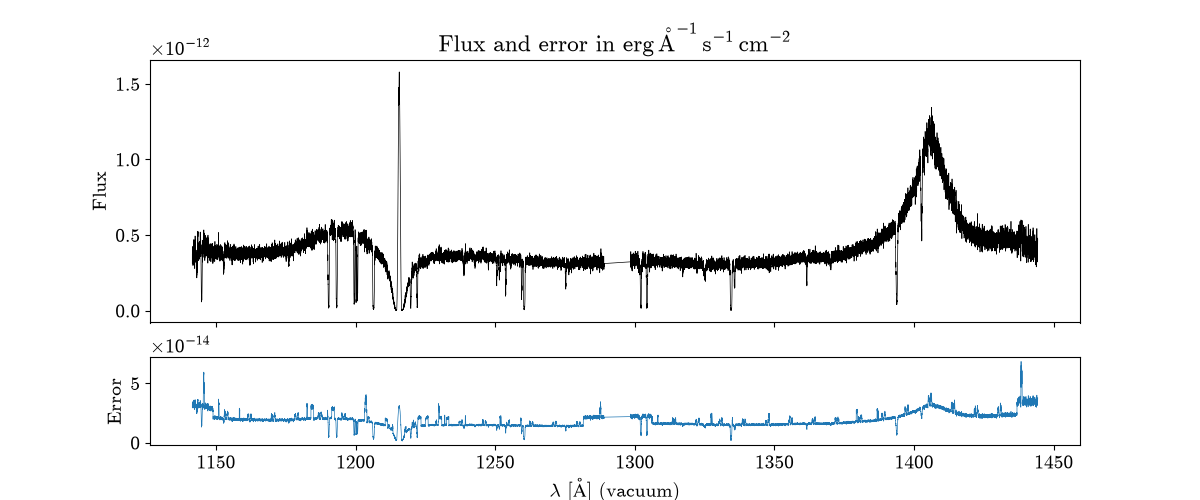

In [8]:
import matplotlib.pyplot as plt

from spectral_diag.plots import plot_raw_spectrum

# Visit with the highest S/N (longest exposure)
spectrum = cos_spectra[1]

fig, axes = plot_raw_spectrum(spectrum)
plt.show()